In [1]:
import ipynb.fs.full.linear_regression as lr

In [2]:
scan = "0020_dscan"
data, cx, cy, hough_params =  lr.read_the_data(scan)

{'enabled': True, 'min_radius': 12, 'max_radius': 30, 'param1': 100, 'param2': 22, 'min_dist': 50, 'stabilise': True, 'hold_frames': 3}


,point,time,x,y,x_rb,y_rb,s0,s1,s2,strain,frame_id,n_circles,cx,cy,radius,image
0,0,2.2064,-0.20,0.0,-0.200043,3.700743e-17,0,887,-887,0.0,5492,1,398,228,21,images/0000.png
1,1,3.2147,-0.16,0.0,-0.159899,3.700743e-17,0,709,-709,0.0,5522,1,386,232,21,images/0001.png
2,2,4.3009,-0.12,0.0,-0.119981,2.220446e-17,0,532,-532,0.0,5550,1,368,232,21,images/0002.png
3,3,5.3422,-0.08,0.0,-0.080062,1.850372e-17,0,355,-355,0.0,5579,1,356,232,20,images/0003.png
4,4,6.4024,-0.04,0.0,-0.039918,9.251859e-18,0,177,-177,0.0,5606,1,342,232,22,images/0004.png
5,5,7.3920,0.00,0.0,0.000000,0.000000e+00,0,0,0,0.0,5635,1,326,232,21,images/0005.png
6,6,8.4482,0.04,0.0,0.039918,-9.251859e-18,0,-177,177,0.0,5664,1,312,236,22,images/0006.png
7,7,9.5197,0.08,0.0,0.080062,-1.850372e-17,0,-355,355,0.0,5693,1,292,236,21,images/0007.png
8,8,10.5754,0.12,0.0,0.119981,-2.220446e-17,0,-532,532,0.0,5720,1,276,236,22,images/0008.png
9,9,11.5647,0.16,0.0,0.159899,-3.700743e-17,0,-709,709,0.0,5749,1,262,234,21,images/0009.png


Scan 0020_dcan was a scan along the x-axis, from x=-0.2 to x=0.2 in 11 steps. The camera was rotated such that the robot's x-axis and the camera's x-axis were aligned (as closely as possible from manual alignment.)

np.polyfit slope and intercept :  -0.04199475065616823 246.87139107611554
stats.linregress slope and intercept -0.04199475065616798 246.8713910761155


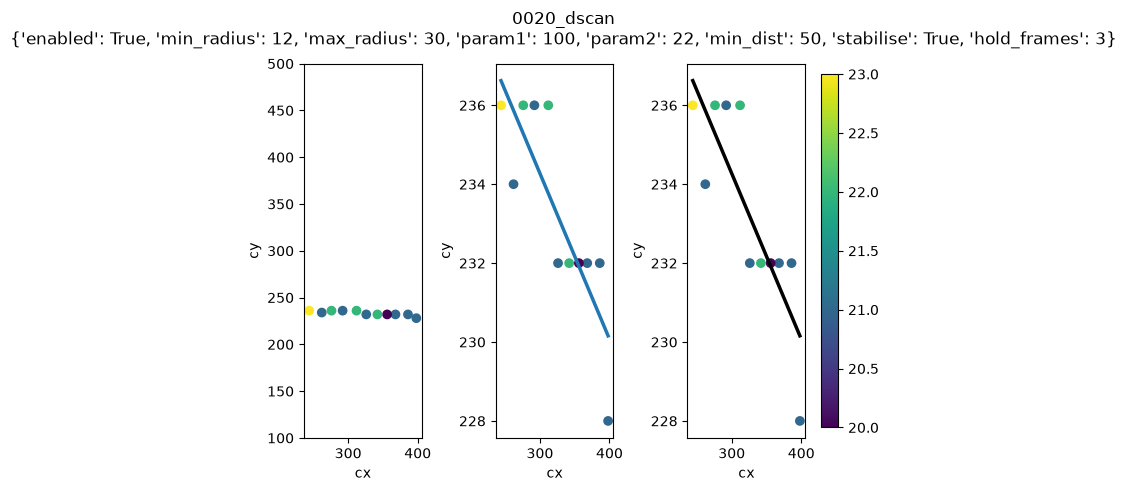

In [3]:
lr.subplot_linear(scan, hough_params, cx, cy, data["radius"], 100, 500, True)

The above plots show the bot does move in a generally straight line with some unexplained variations.
Possible causes for the variations: 
- the hough transform flickering/varying where it thinks the centre of the circle is
- random movements of the delta bot
- the camera / axis not being completely aligned

Because the axis should be aligned - I want to look at how the x values vary:
- the commanded x; 
- the position the step counts give, x_rb; 
- and the x value of the identified circle, cx 
 

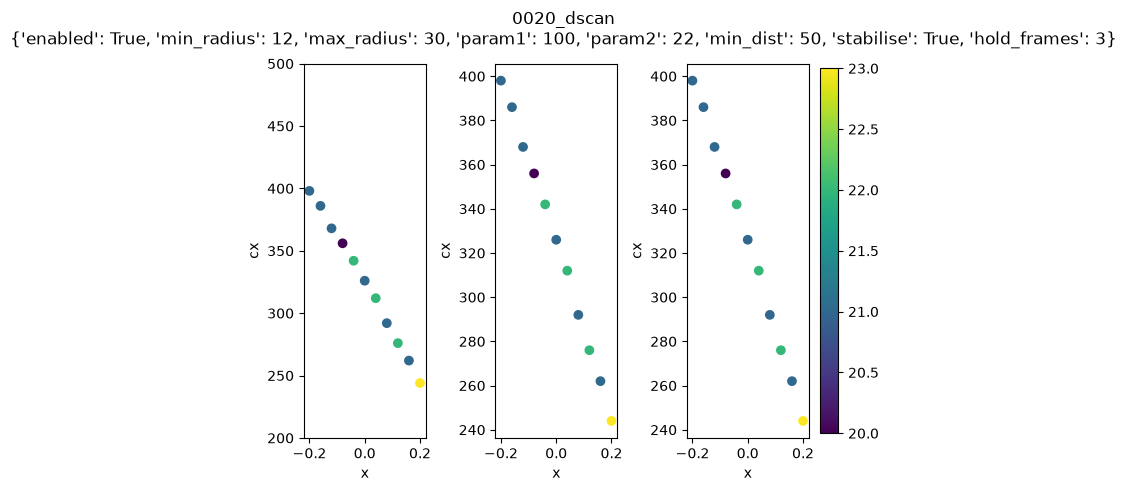

In [4]:
#commanded x and cx
lr.subplot_linear(scan, hough_params, data["x"], cx, data["radius"], 200, 500, False)

Linear relationship is expected? As x is increased, cx should also increase (or, depending on whether direction has been set correctly, decrease).

Investigating why the cy-value changes:
- does the radius have any link to it? 

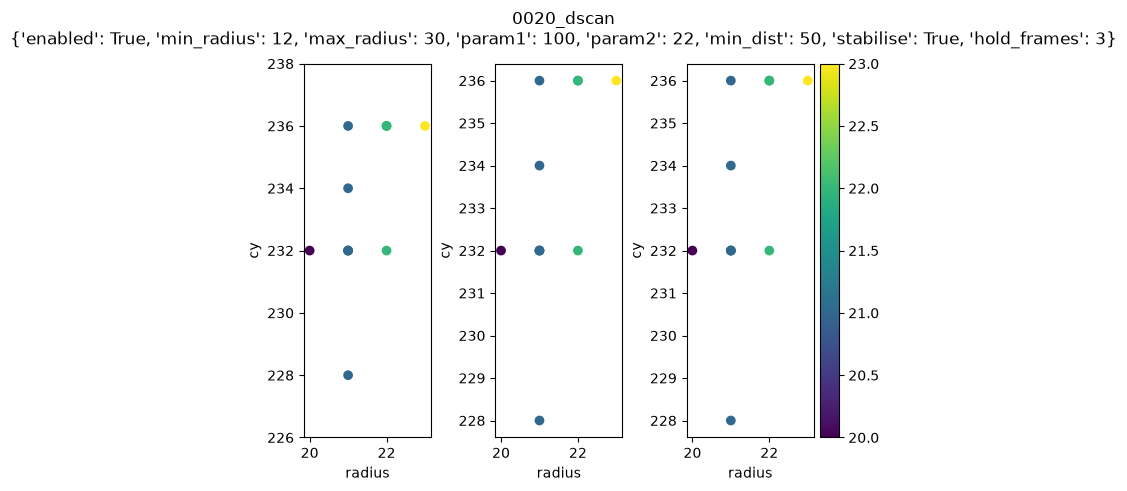

In [5]:
lr.subplot_linear(scan, hough_params, data["radius"], data["cy"], data["radius"], 226, 238, False)

<h3>Investigating other values</h3>

What are x_rb and y_rb?

Remeber this scan was across the x axis only. 

(<Figure size 640x480 with 2 Axes>, <Axes: xlabel='x_rb', ylabel='y_rb'>)

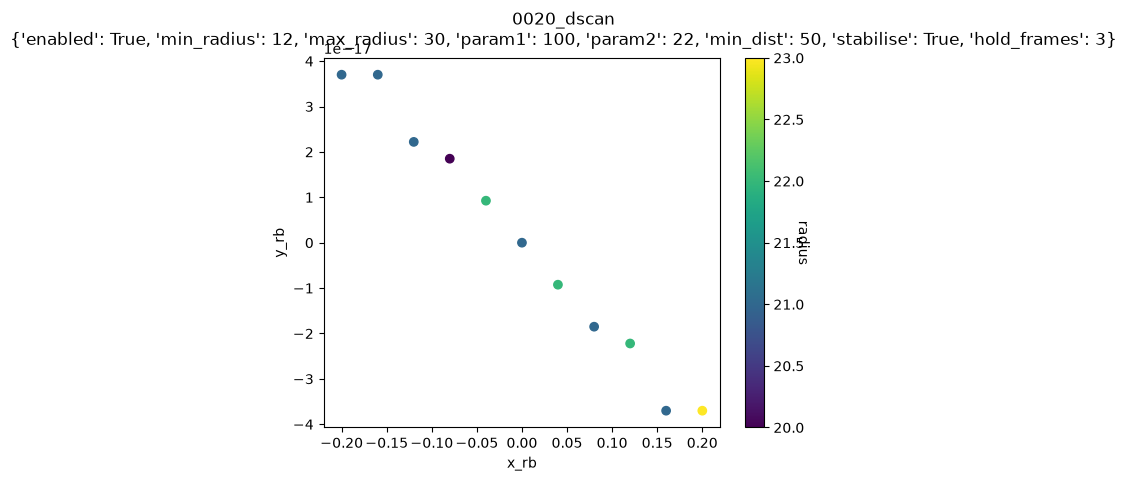

In [ ]:
lr.single_plot(scan, hough_params, data["x_rb"], data["y_rb"], data["radius"], None, None, False)

(<Figure size 640x480 with 2 Axes>, <Axes: xlabel='x', ylabel='x_rb'>)

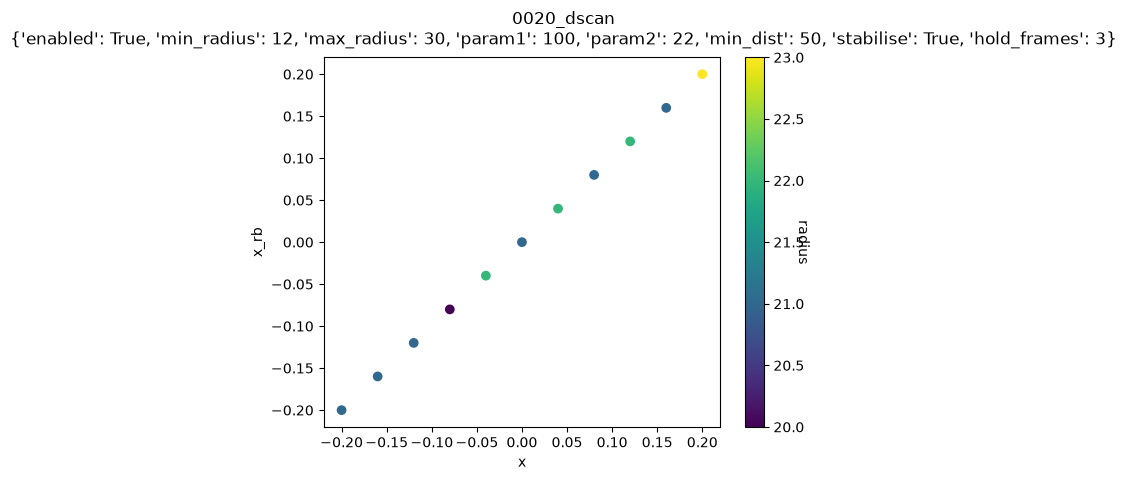

In [8]:
lr.single_plot(scan, hough_params, data["x"], data["x_rb"], data["radius"], None, None, False)

So x_rb is maybe just the readout of x from the motors? basically the same as x?

(<Figure size 640x480 with 2 Axes>, <Axes: xlabel='y', ylabel='y_rb'>)

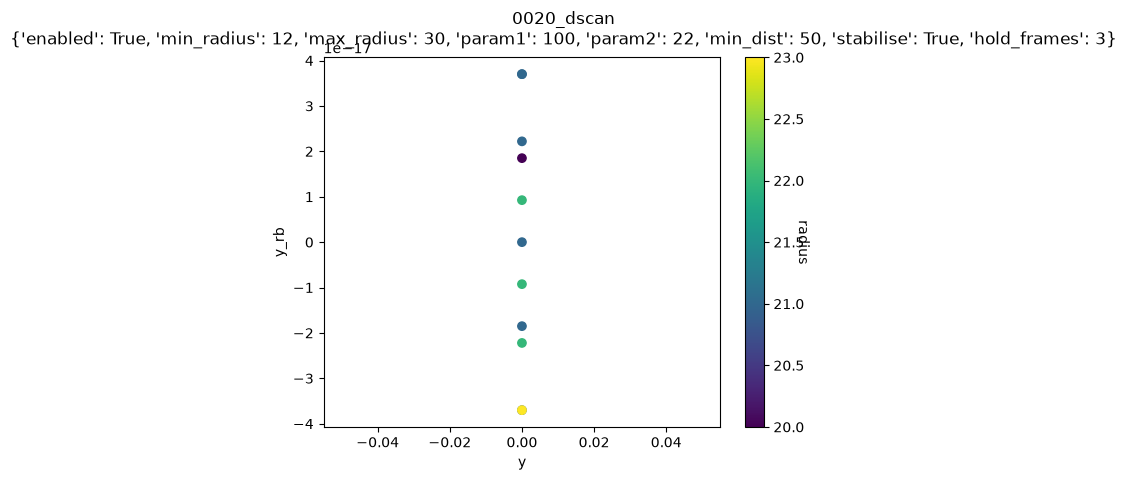

In [9]:
lr.single_plot(scan, hough_params, data["y"], data["y_rb"], data["radius"], None, None, False)

The y_rb values are all *10^-17 so are ~0 --> also seems to just be basically the same as y.

Are s0, s1, s2 the counts??
x-axis scan, m0 doesn't seem to move. s0 is 0 the whole time --> makes sense.

(<Figure size 640x480 with 2 Axes>, <Axes: xlabel='s1', ylabel='s2'>)

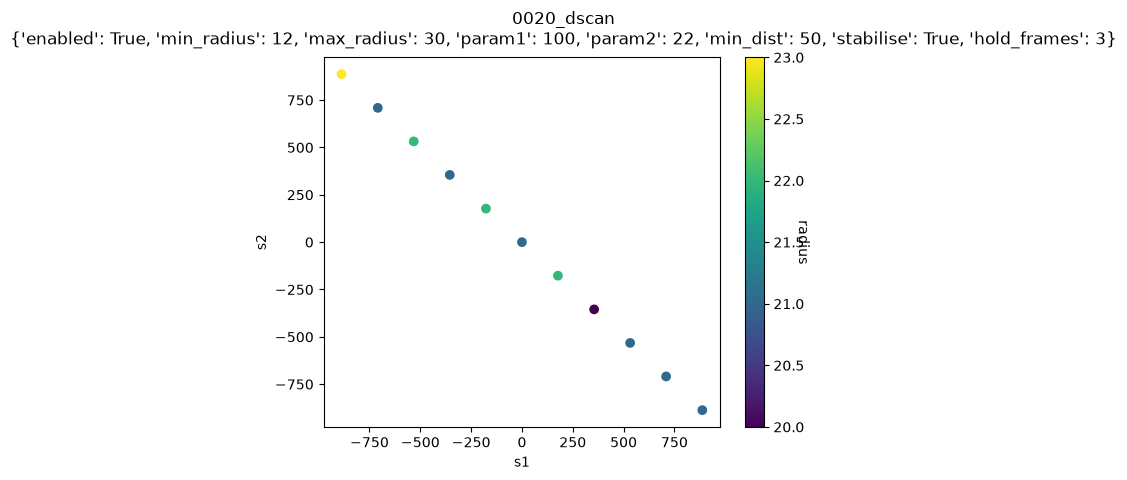

In [12]:
lr.single_plot(scan, hough_params, data["s1"], data["s2"], data["radius"], None, None, False)

s1 = -s2.
In raw motor scans m1 shows weird behaviour. but not here. are these values the counts? 


Compare to the m1 and m2 scans - try and do the same limits

In [42]:
#m1 scan
scan_42 = "0042_dscan"
data_42, cx_42, cy_42, hough_params_42 =  lr.read_the_data(scan_42)

#m2 scan
scan_43 = "0043_dscan" #or scan 30
data_43, cx_43, cy_43, hough_params_43 =  lr.read_the_data(scan_43)

#x scan again
scan_44 = "0044_dscan" #or scan 30
data_44, cx_44, cy_44, hough_params_44 =  lr.read_the_data(scan_44)

{'enabled': True, 'min_radius': 12, 'max_radius': 30, 'param1': 100, 'param2': 22, 'min_dist': 50, 'stabilise': True, 'hold_frames': 3}


,point,time,m0,m1,m2,x_rb,y_rb,s0,s1,s2,strain,frame_id,n_circles,cx,cy,radius
0,0,2.1112,0,887,0,-0.100021,-0.057747,0,887,0,0.072184,5399,1,266,256,18
1,1,3.1055,0,710,0,-0.080062,-0.046224,0,710,0,0.057780,5426,2,268,256,18
2,2,4.0830,0,532,0,-0.059990,-0.034635,0,532,0,0.043294,5451,1,276,252,20
3,3,5.0103,0,355,0,-0.040031,-0.023112,0,355,0,0.028890,5478,1,280,248,18
4,4,5.9857,0,177,0,-0.019959,-0.011523,0,177,0,0.014404,5503,1,288,244,19
5,5,6.9121,0,0,0,0.000000,0.000000,0,0,0,0.000000,5530,1,294,240,19
6,6,7.8886,0,-177,0,0.019959,0.011523,0,-177,0,-0.014404,5556,1,304,236,19
7,7,8.8459,0,-355,0,0.040031,0.023112,0,-355,0,-0.028890,5582,1,310,232,19
8,8,9.8064,0,-532,0,0.059990,0.034635,0,-532,0,-0.043294,5609,1,320,226,18
9,9,10.7839,0,-710,0,0.080062,0.046224,0,-710,0,-0.057780,5636,1,328,222,19


{'enabled': True, 'min_radius': 12, 'max_radius': 30, 'param1': 100, 'param2': 22, 'min_dist': 50, 'stabilise': True, 'hold_frames': 3}


,point,time,m0,m1,m2,x_rb,y_rb,s0,s1,s2,strain,frame_id,n_circles,cx,cy,radius
0,0,2.1445,0,0,-887,-0.100021,0.057747,0,0,-887,-0.072184,6268,1,256,220,19
1,1,3.1041,0,0,-710,-0.080062,0.046224,0,0,-710,-0.057780,6295,1,258,222,18
2,2,4.0804,0,0,-532,-0.059990,0.034635,0,0,-532,-0.043294,6323,1,266,226,18
3,3,5.1057,0,0,-355,-0.040031,0.023112,0,0,-355,-0.028890,6349,1,274,230,18
4,4,6.0643,0,0,-177,-0.019959,0.011523,0,0,-177,-0.014404,6376,1,280,234,19
5,5,7.0416,0,0,0,0.000000,0.000000,0,0,0,0.000000,6403,1,288,238,18
6,6,8.0321,0,0,177,0.019959,-0.011523,0,0,177,0.014404,6428,1,296,242,19
7,7,8.9574,0,0,355,0.040031,-0.023112,0,0,355,0.028890,6456,1,304,246,19
8,8,9.9809,0,0,532,0.059990,-0.034635,0,0,532,0.043294,6483,1,312,250,18
9,9,10.9702,0,0,710,0.080062,-0.046224,0,0,710,0.057780,6510,1,320,252,17


{'enabled': True, 'min_radius': 12, 'max_radius': 30, 'param1': 100, 'param2': 22, 'min_dist': 50, 'stabilise': True, 'hold_frames': 3}


,point,time,x,y,x_rb,y_rb,s0,s1,s2,strain,frame_id,n_circles,cx,cy,radius
0,0,2.1327,-0.20,0.0,-0.200043,3.700743e-17,0,887,-887,0.0,7306,1,226,238,20
1,1,3.0782,-0.16,0.0,-0.159899,3.700743e-17,0,709,-709,0.0,7332,1,232,240,18
2,2,4.0207,-0.12,0.0,-0.119981,2.220446e-17,0,532,-532,0.0,7359,1,246,238,19
3,3,5.0173,-0.08,0.0,-0.080062,1.850372e-17,0,355,-355,0.0,7385,1,260,240,18
4,4,5.9605,-0.04,0.0,-0.039918,9.251859e-18,0,177,-177,0.0,7412,2,274,240,19
5,5,6.9519,0.00,0.0,0.000000,0.000000e+00,0,0,0,0.0,7440,1,288,238,19
6,6,7.9745,0.04,0.0,0.039918,-9.251859e-18,0,-177,177,0.0,7467,1,304,240,19
7,7,8.9650,0.08,0.0,0.080062,-1.850372e-17,0,-355,355,0.0,7496,1,320,238,19
8,8,10.0193,0.12,0.0,0.119981,-2.220446e-17,0,-532,532,0.0,7522,1,338,236,18
9,9,10.9760,0.16,0.0,0.159899,-3.700743e-17,0,-709,709,0.0,7548,1,354,236,19


(<Figure size 640x480 with 2 Axes>, <Axes: xlabel='cx', ylabel='cy'>)

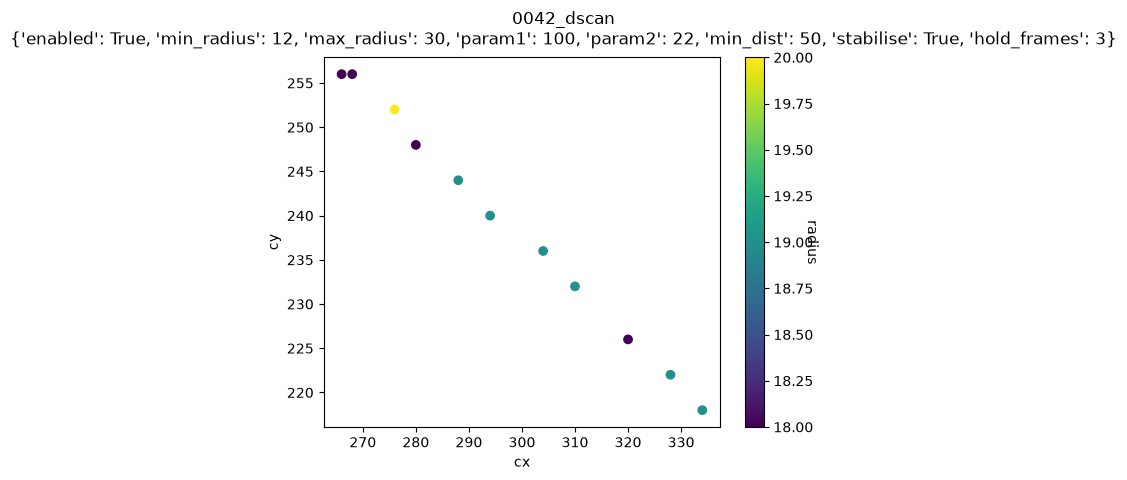

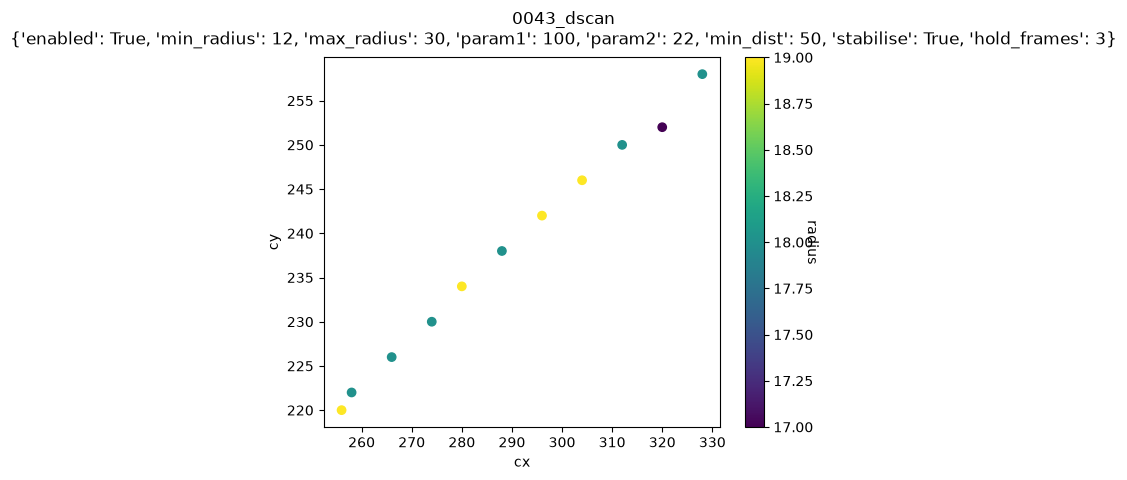

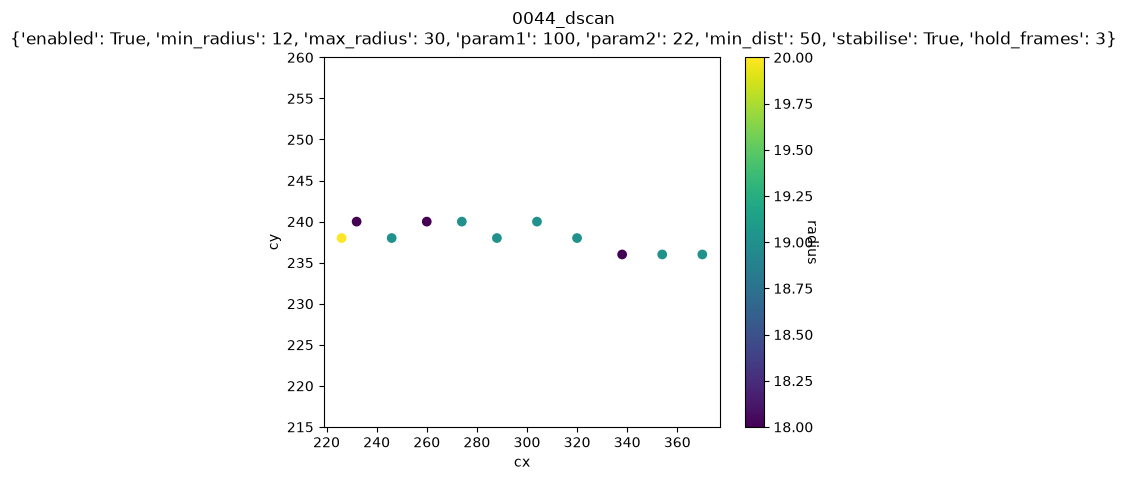

In [56]:
#m1
fig_42, ax_42 = lr.single_plot(scan_42, hough_params_42, cx_42, cy_42, data_42["radius"], None, None, False)
#m2
lr.single_plot(scan_43, hough_params_43, cx_43, cy_43, data_43["radius"], None, None, False)
#x
lr.single_plot(scan_44, hough_params_44, cx_44, cy_44, data_44["radius"], 215, 260, False)


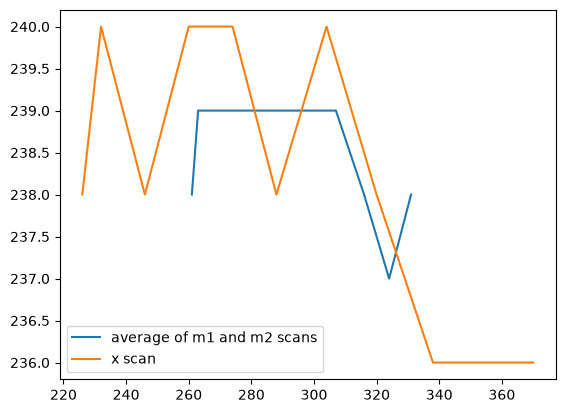

In [63]:
# lr.single_plot(scan_44, hough_params_44, cx_44, cy_44, data_44["radius"], 215, 260, False)

# lr.single_plot(scan_42, hough_params_42, (cx_42+cx_43)/2, (cy_42+cy_43)/2, data_42["radius"], 215, 260, False)
import matplotlib.pyplot as plt
plt.plot((cx_42+cx_43)/2, (cy_42+cy_43)/2, label="average of m1 and m2 scans")
plt.plot(cx_44, cy_44, label="x scan")
plt.legend()

The y values in the x scan are similar to the average of the two motor scans - as expected. The x values are a much wider range - probably because both axes/motors are working together to move, rather than just one moving and pushing against the other. 
--> I think s0,s1,s2 probably are the counts of the stepper motors. 

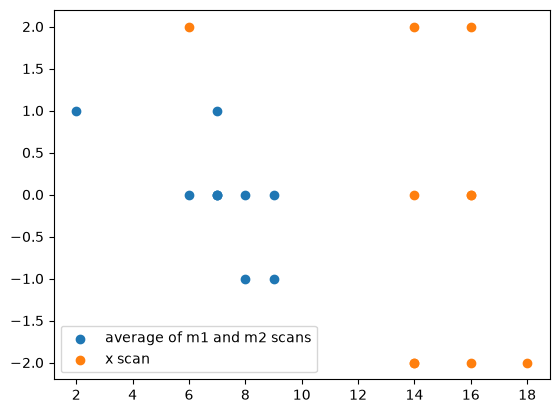

In [ ]:
#find mid point and subtract it .

plt.scatter((cx_42.diff()+cx_43.diff())/2, (cy_42.diff()+cy_43.diff())/2, label="average of m1 and m2 scans")
plt.scatter(cx_44.diff(), cy_44.diff(), label="x scan")
plt.legend()